# 05, Residual phenotype: is there a second diagnosis?

**Place in the argument.** Track 1, clinical check. It separates a residual trait
from a gap in annotation before any second diagnosis is proposed.

**Main output.** A term × disease matrix and a sweep of the nephrocalcinosis gene panel. It
does not show that a trait without published support is incompatible with MVA.

## The biological question

**Which of the patient's traits does MVA not explain, and does any of them demand a second
diagnosis?**

The nephrocalcinosis is **present from birth**. Nephrocalcinosis of
prematurity is acquired and postnatal (it develops over weeks of furosemide, parenteral
nutrition and calcium load). If it is present at birth it is antenatal, and **the prior flips**.

## A reading to avoid

The ranking measured that several traits add little semantic support to the MVA model. The
tempting reading would be: *"MVA does not explain them, therefore there is a second diagnosis"*.

**That would turn the incompleteness of a database into biology.** Growth retardation appears in
**93.5 %** of MVA1 cases: it is not a mysterious residual.

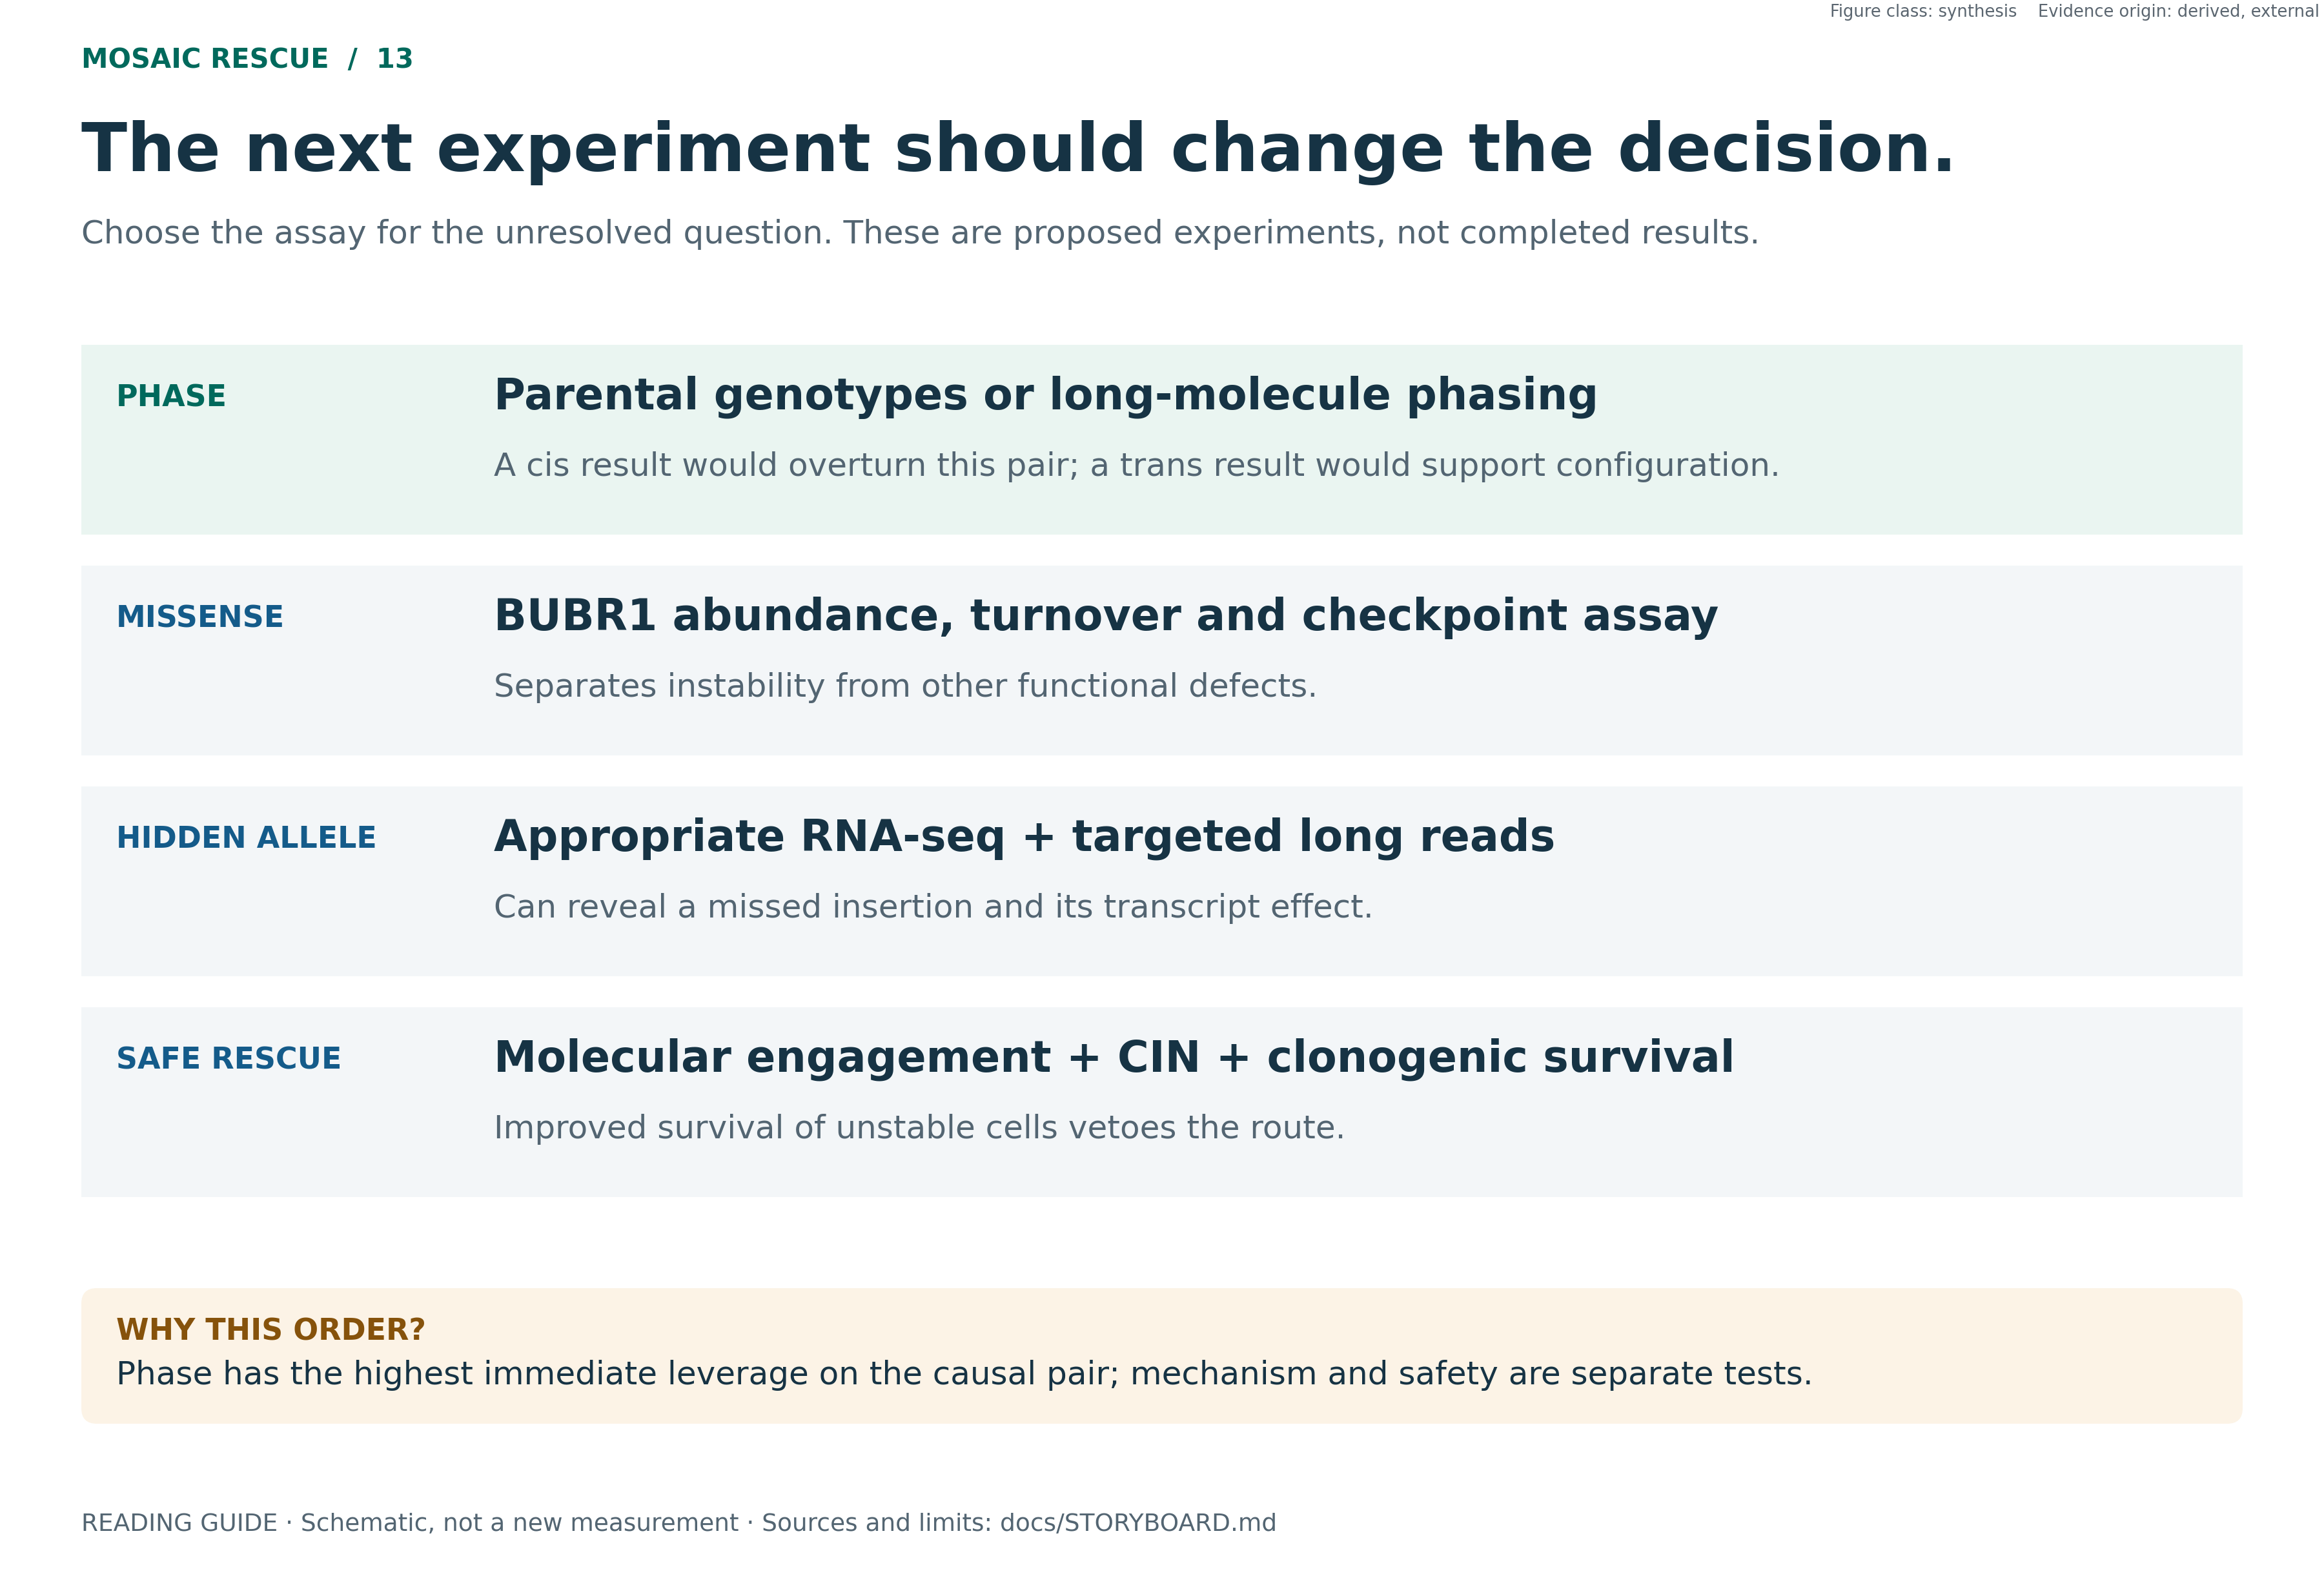

**`SYNTHESIS`, DERIVED / EXTERNAL.** Decision map. The residual phenotype also needs clinical review; it does not establish a second diagnosis. Reviewed figure, embedded without re-running the original analysis, [sources and limits](../docs/STORYBOARD.md), [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("Environment ready. Figures render inline, each with a provenance caption.")

Environment ready. Figures render inline, each with a provenance caption.


In [2]:
fl.labels("Interpretation", "Biases that are not corrected")

## Method, the right question is membership, not the score

The *leave-one-out* contribution is **not** a term's absolute support: under Best Match Average,
removing a term that scores below the mean **raises** the average. So the right measure is
**whether the term is annotated in the disease model**.

In [3]:
PREP = pickle.load(io.open("work/hpo/prepared.pkl", "rb"))
mva = [m for m in PREP["models"] if m.disease_id == "OMIM:257300"]
terms = mva[0].terms if mva else set()
print(f"  model OMIM:257300 (MVA1), {mva[0].n_raw} terms annotated before propagation")

PROBAND = [
 ("HP:0002859", "Rhabdomyosarcoma",           "38.7 % (malignancy)"),
 ("HP:0004322", "Short stature",              "93.5 % (growth)"),
 ("HP:0001518", "Small for gestational age",  "93.5 % (growth)"),
 ("HP:0001508", "Failure to thrive",          "93.5 % (growth)"),
 ("HP:0001622", "Premature birth",            "not quantified"),
 ("HP:0003202", "Muscle atrophy",             "not quantified"),
 ("HP:0000121", "Nephrocalcinosis",           "no; series report generic renal dysfunction, 12.9 %"),
]
print()
print(f"  {'trait':<28}{'annotated in HPO':>18}{'MVA1 literature':>46}")
for hid, lab, lit in PROBAND:
    print(f"  {lab:<28}{('yes' if hid in terms else 'no'):>18}{lit:>46}")

  model OMIM:257300 (MVA1), 59 terms annotated before propagation

  trait                         annotated in HPO                               MVA1 literature
  Rhabdomyosarcoma                           yes                           38.7 % (malignancy)
  Short stature                              yes                               93.5 % (growth)
  Small for gestational age                  yes                               93.5 % (growth)
  Failure to thrive                           no                               93.5 % (growth)
  Premature birth                             no                                not quantified
  Muscle atrophy                              no                                not quantified
  Nephrocalcinosis                            nono; series report generic renal dysfunction, 12.9 %


### Main figure 1. HPO term × disease model matrix

A yes/no bar answers in binary a question that is not binary. The right measure is the one the
engine itself uses: **Resnik** similarity, the information content of the most informative common
ancestor between the proband's term and the best-matching term of the model, in bits.

> **Why terms are not classified as "ancestor annotated".** The corpus models carry their terms
> **propagated to the root**. In that representation "the model annotates an ancestor" is always
> true (the root is in all of them), so the category distinguishes nothing. It was tried, came out
> uniform, and was dropped. What does distinguish: whether the term **is covered** (annotated, or
> annotated with something more specific) and **how many bits** the best match is worth.

In [4]:
from src.phenotype.semantic import ancestors

PAR, IC, NAMES = PREP["parents"], PREP["ic"], PREP["names"]
MODELS = PREP["models"]
cache = {}
PT = [p[0] for p in PROBAND]

def bestmatch(t, m):
    """Resnik: IC of the most informative common ancestor, over the model's best term.
    It is exactly the BMA ingredient the ranking uses."""
    at = ancestors(t, PAR, cache)
    best = 0.0
    for mt in m.terms:
        sh = at & ancestors(mt, PAR, cache)
        if sh:
            v = max(IC.get(a, 0.0) for a in sh)
            if v > best:
                best = v
    return best

MVA_IDS = ["OMIM:257300", "OMIM:614114", "OMIM:617598"]
byid = {}
for m in MODELS:
    byid.setdefault(m.disease_id, m)

# Columns are not chosen by hand: the three MVA models, then the models most similar to the
# proband's complete profile by BMA.
from src.phenotype.semantic import resnik_bma
scored = sorted(((resnik_bma(PT, m.terms, IC, PAR, cache), m) for m in byid.values()),
                key=lambda x: -x[0])
COLS, seen_id = [], set()
for did in MVA_IDS:
    if did in byid:
        COLS.append(byid[did]); seen_id.add(did)
for sc, m in scored:
    if len(COLS) >= 12:
        break
    if m.disease_id not in seen_id:
        COLS.append(m); seen_id.add(m.disease_id)

BM = np.array([[bestmatch(t, m) for m in COLS] for t in PT])
COV = np.array([[t in m.terms for m in COLS] for t in PT])
ICT = {t: IC.get(t, 0.0) for t in PT}

print(f"  distinct disease models in the corpus : {len(byid):,}")
print(f"  columns: {len(COLS)}  ({len(MVA_IDS)} MVA + "
      f"{len(COLS)-len(MVA_IDS)} by similarity to the complete profile)")
print(f"  maximum IC in the corpus: {max(IC.values()):.2f} bits")

  distinct disease models in the corpus : 9,155
  columns: 12  (3 MVA + 9 by similarity to the complete profile)
  maximum IC in the corpus: 8.57 bits


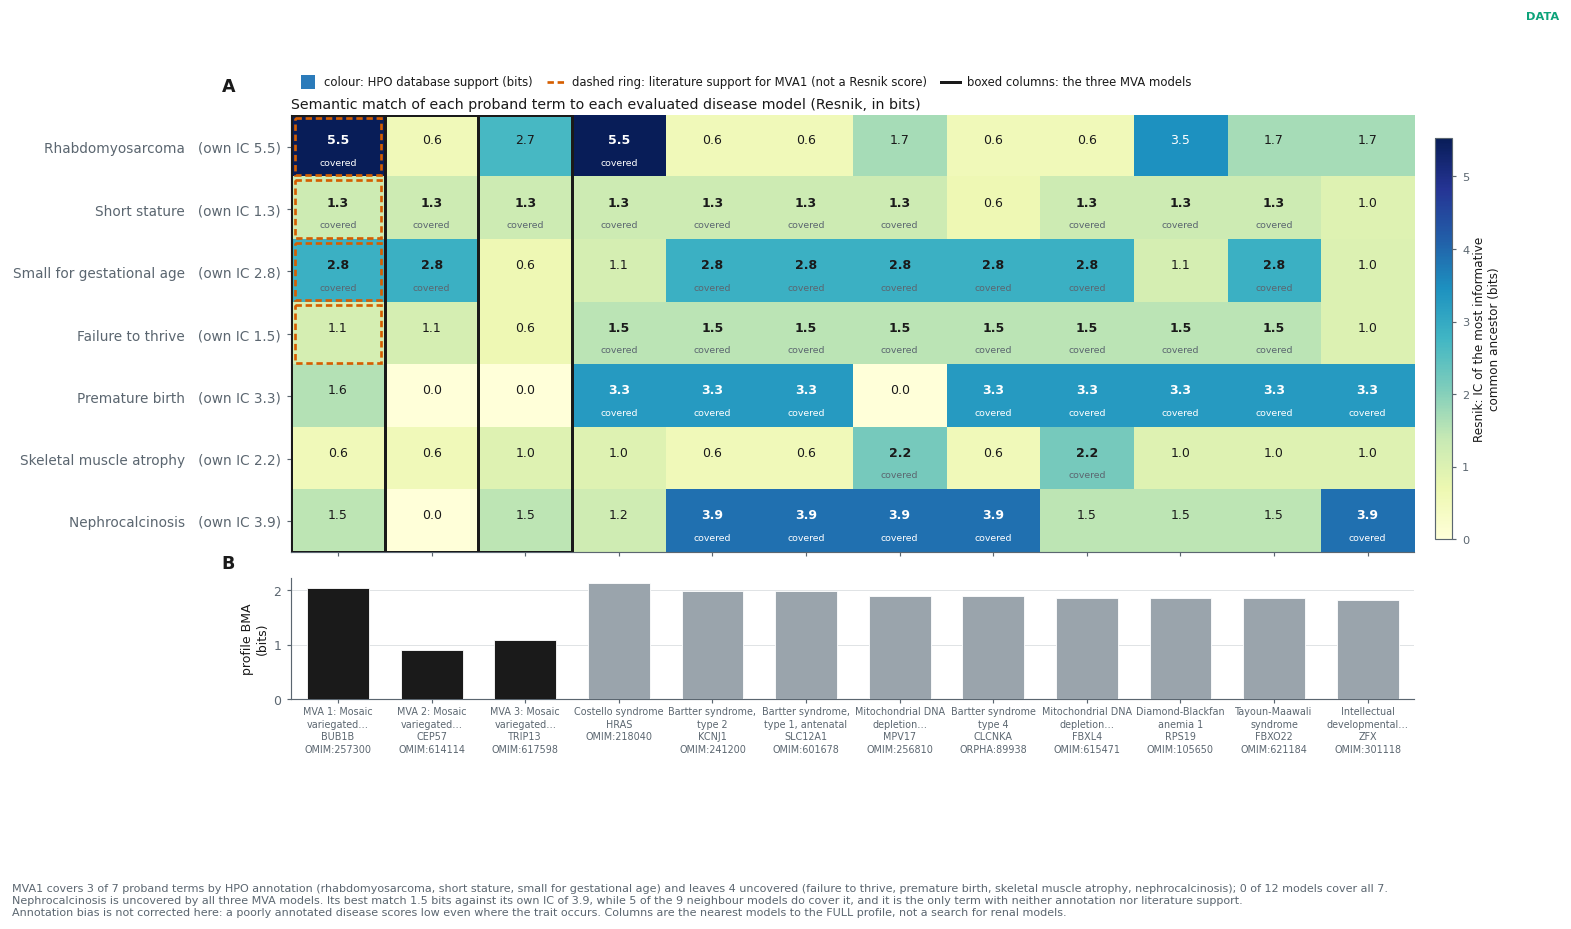

**Main figure 1: HPO term x disease model matrix.** EXP-018, EXP-019; class `DATA` (scientific figure); evidence origin EXTERNAL and DERIVED.

*Interpretation:* where each trait fits and where it does not, in bits rather than yes/no, against the 12 models evaluated, with their real disease names. MVA1 covers 3 of the 7 traits and leaves 4 uncovered. None of the three MVA models covers nephrocalcinosis: its best match is 1.5 bits against its own IC of 3.9, whereas the Bartter models do cover it. The dashed ring marks MVA1 literature support, which is kept separate from the colour and is never turned into a score.

*Biases that are not corrected:* that a second diagnosis is needed. IC is set by the corpus: a sparsely annotated disease scores low even when the trait occurs in it. The columns are neighbours of the complete profile, not a search for renal models.

<sub>Data: work/hpo/prepared.pkl + work/hpo/phenotype.hpoa (disease names). Library: matplotlib. Provenance: figures/pub/fig05_hpo_disease_matrix.svg + .png 300 dpi.</sub>

In [5]:
from src.figures import fig05_hpo as FH

MTX = FH.prepare([t for t, _l in FH.PROBAND], dict(FH.PROBAND), FH.LIT_MVA1)
fig = FH.build(MTX)
_pt, _cov, _bm = MTX["terms"], MTX["covered"], MTX["bestmatch"]
_mv = [j for j, c in enumerate(MTX["cols"]) if c["id"] in FH.MVA_IDS]
_cov1 = [MTX["term_labels"][_pt[i]] for i in range(len(_pt)) if _cov[i, _mv[0]]]
_unc1 = [MTX["term_labels"][_pt[i]] for i in range(len(_pt)) if not _cov[i, _mv[0]]]
_inef = MTX["nephro_index"]
fl.pub(fig, "Main figure 1: HPO term x disease model matrix",
       "EXP-018, EXP-019", "EXTERNAL+DERIVED", "DATA",
       f"where each trait fits and where it does not, in bits rather than yes/no, against the "
       f"{len(MTX['cols'])} models evaluated, with their real disease names. MVA1 covers "
       f"{len(_cov1)} of the {len(_pt)} traits and leaves {len(_unc1)} uncovered. None of the "
       f"three MVA models covers nephrocalcinosis: its best match is {_bm[_inef, _mv[0]]:.1f} bits "
       f"against its own IC of {MTX['ic_terms'][_pt[_inef]]:.1f}, whereas the Bartter models do "
       f"cover it. The dashed ring marks MVA1 literature support, which is kept separate from the "
       f"colour and is never turned into a score.",
       "that a second diagnosis is needed. IC is set by the corpus: a sparsely annotated disease "
       "scores low even when the trait occurs in it. The columns are neighbours of the complete "
       "profile, not a search for renal models.",
       source="work/hpo/prepared.pkl + work/hpo/phenotype.hpoa (disease names)",
       lib="matplotlib", slug="fig05_hpo_disease_matrix")

### The two checks, crossed

A trait is **residual** only if it fails **both** checks: not annotated in the HPO model
**and** not supported by the MVA1 literature
([Neurol Sci 2022 series](https://doi.org/10.1007/s10072-022-06247-w)).

In [6]:
from IPython.display import Markdown, display
LIT = {"HP:0002859": "yes, 38.7 %", "HP:0004322": "yes, 93.5 %", "HP:0001518": "yes, 93.5 %",
       "HP:0001508": "yes, 93.5 %", "HP:0001622": "no data", "HP:0003202": "no data",
       "HP:0000121": "**no**"}
VERD = {"HP:0000121": "**residual on both checks**"}
md = ["| Trait | In the MVA1 HPO model | In the MVA1 literature | Reading |", "|---|---|---|---|"]
for hid, lab, _l in PROBAND:
    ann = "yes" if hid in terms else "**no**"
    lit = LIT[hid]
    if hid in VERD:
        r = VERD[hid]
    elif hid in terms:
        r = "explained"
    elif lit.startswith("yes"):
        r = "annotation gap"
    else:
        r = "undecided: no data"
    md.append(f"| {lab} | {ann} | {lit} | {r} |")
display(Markdown("\n".join(md)))

| Trait | In the MVA1 HPO model | In the MVA1 literature | Reading |
|---|---|---|---|
| Rhabdomyosarcoma | yes | yes, 38.7 % | explained |
| Short stature | yes | yes, 93.5 % | explained |
| Small for gestational age | yes | yes, 93.5 % | explained |
| Failure to thrive | **no** | yes, 93.5 % | annotation gap |
| Premature birth | **no** | no data | undecided: no data |
| Muscle atrophy | **no** | no data | undecided: no data |
| Nephrocalcinosis | **no** | **no** | **residual on both checks** |

> **Consequence for the project:** the mixed-diagnosis argument **narrows from four traits to
> one**. Weaker in number and much stronger in quality, because that one survives both checks.

## Primary result 2. The renal panel sweep

With the allele join **already fixed**, which was the real reason to repeat it: the fix recovered
420 positions and could have uncovered a renal allele that was being lost before.

It includes the explicit `MAGED2` check the panel itself requires: it is X-linked recessive, and
in a male **one** hemizygous variant is enough, so a "biallelic" filter would miss it.

In [7]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

panel = {l.split("#")[0].strip() for l in io.open("config/panels/nephrocalcinosis.txt",
                                                  encoding="utf-8") if l.split("#")[0].strip()}
rows = load("work/gw/highmod_ann.tsv", patient_vcf())
hits = [v for v in rows if v.gene in panel and v.impact in ("HIGH", "MODERATE")]
seen, uniq = set(), []
for v in hits:
    k = (v.loc, v.allele, v.gene)
    if k not in seen:
        seen.add(k); uniq.append(v)
freqs = sorted([v.max_af for v in uniq if v.max_af is not None])
rare = [v for v in uniq if v.max_af is None or v.max_af < 0.005]
maged2 = [v for v in rows if v.gene == "MAGED2"]
print(f"  panel genes: {len(panel)}   HIGH/MODERATE alleles: {len(uniq)}")
print(f"  rarest allele in the panel: {min(freqs)*100:.1f} %")
print(f"  rare at the panel's own threshold (AF < 0.005): {len(rare)}")
print(f"  MAGED2 variants, any impact: {len(maged2)}")

  panel genes: 28   HIGH/MODERATE alleles: 23
  rarest allele in the panel: 1.0 %
  rare at the panel's own threshold (AF < 0.005): 0
  MAGED2 variants, any impact: 0


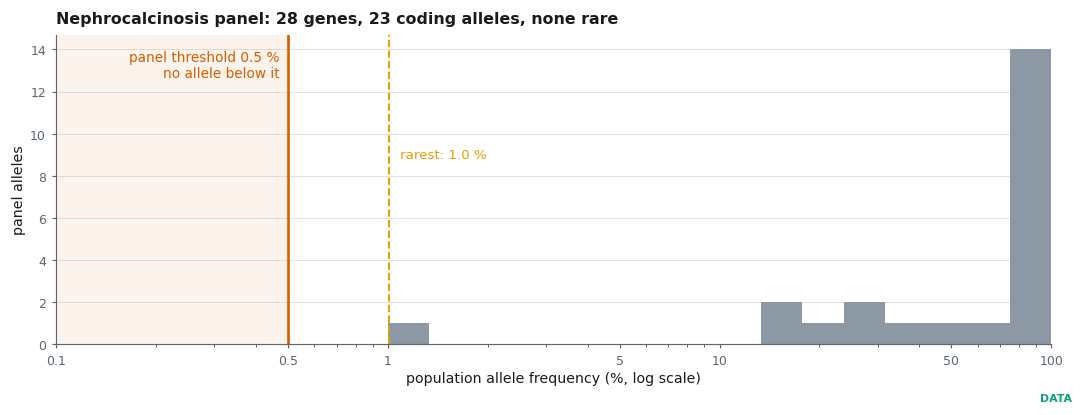

**Main figure 2: The renal panel, by allele frequency.** EXP-017; class `DATA` (scientific figure); evidence origin MEASURED.

*Interpretation:* all 23 HIGH/MODERATE alleles in the panel are common polymorphisms. The rarest is at 1.0 %, 2 times the panel's own 0.5 % threshold. The two high-impact start-lost calls that drew attention are at 51 % and 81 %. And MAGED2 contributes no variant (0).

*Biases that are not corrected:* that a tubulopathy has been ruled out. It is a coding sweep: it does not see regulatory, deep-intronic or structural variants in these genes, which were not adjudicated here.

<sub>Provenance: config/panels/nephrocalcinosis.txt + corrected allele join.</sub>

In [8]:
fig, ax = plt.subplots(figsize=(9.0, 3.4))
vals = np.array(sorted([v.max_af * 100 for v in uniq if v.max_af is not None]))
bins = np.logspace(np.log10(0.1), np.log10(100), 25)
ax.axvspan(0.1, 0.5, color=fl.DEAD, alpha=0.07, lw=0)
ax.hist(vals, bins=bins, color=fl.FLOW, lw=0)
ax.axvline(0.5, color=fl.DEAD, lw=1.6)
ax.text(0.47, ax.get_ylim()[1] * 0.95, "panel threshold 0.5 %\nno allele below it",
        ha="right", va="top", fontsize=8.2, color=fl.DEAD)
ax.axvline(vals.min(), color=fl.OPEN, ls="--", lw=1.2)
ax.text(vals.min() * 1.08, ax.get_ylim()[1] * 0.6, f"rarest: {vals.min():.1f} %", fontsize=8,
        color=fl.OPEN)
ax.set_xscale("log"); ax.set_xlim(0.1, 100)
ax.set_xticks([0.1, 0.5, 1, 5, 10, 50, 100]); ax.set_xticklabels(["0.1", "0.5", "1", "5", "10", "50", "100"])
ax.set_xlabel("population allele frequency (%, log scale)")
ax.set_ylabel("panel alleles"); ax.grid(axis="y")
fl.title(ax, f"Nephrocalcinosis panel: {len(panel)} genes, {len(uniq)} coding alleles, none rare")

fl.done(fig, "Main figure 2: The renal panel, by allele frequency", "EXP-017", "MEASURED", "DATA",
        f"all {len(uniq)} HIGH/MODERATE alleles in the panel are common polymorphisms. The rarest "
        f"is at {vals.min():.1f} %, {vals.min()/0.5:.0f} times the panel's own 0.5 % threshold. The two high-impact "
        f"start-lost calls that drew attention are at 51 % and 81 %. And MAGED2 contributes no "
        f"variant ({len(maged2)}).",
        "that a tubulopathy has been ruled out. It is a coding sweep: it does not see regulatory, "
        "deep-intronic or structural variants in these genes, which were not adjudicated here.",
        prov="config/panels/nephrocalcinosis.txt + corrected allele join")

## Robustness, the question that decides is not computational

Antenatal Bartter syndrome produces severe **poly**hydramnios from weeks 18 to 22. MVA is
associated with **oligo**hydramnios. **They are opposites**: one line of the obstetric history
decides.

## Decision

| Branch | Status |
|---|---|
| Coding sweep of the renal panel | **Negative** |
| Growth and failure to thrive as residual | **Negative**: an annotation gap |
| Premature birth | **Parked**: contextual, not quantified |
| Muscle atrophy | **Parked**: no data to decide |
| **Nephrocalcinosis** | **Unresolved, priority residual** |

### What it does not show

It does not rule out a tubulopathy: the sweep is **coding**. And it does not show that the
nephrocalcinosis is a second diagnosis, only that MVA series do not describe it.

### Falsifier, and it is free

It is already in the clinical record: hypokalaemic, hypochloraemic metabolic alkalosis, raised
renin and aldosterone, a high urinary calcium/creatinine ratio. **If they are normal, the
hypothesis dies without spending a core-hour.**

### Next move: among the highest-value questions in the project

**Was there polyhydramnios or oligohydramnios in the pregnancy?** It is a question to the
clinical team, not a computation.